# MBPO vs PPO on Flappy Bird

Comparison of **Model-Based Policy Optimization (MBPO)** and **Proximal Policy Optimization (PPO)** trained on Flappy Bird. Training metrics are loaded from TensorBoard logs. Figures are formatted for academic publication.

## 1. Imports & Global Style

In [ ]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import uniform_filter1d
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ── Publication style — matches reference: white bg, ticks-only axes ──────────
sns.set_theme(style="ticks", context="paper", font_scale=1.35)
mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "grid.color": "0.75",
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "0.80",
})

# ── Palette — Prussian blue / crimson / amber / gold (+ tints for early runs) ─
PALETTE = {
    "PPO (early)":  "#457B9D",   # steel-blue tint of #003049
    "PPO (final)":  "#003049",   # Prussian blue
    "MBPO (early)": "#F77F00",   # orange
    "MBPO (final)": "#D62828",   # crimson
}
# Flat algo palette for distribution plots
ALGO_PALETTE = {"PPO": "#003049", "MBPO": "#D62828"}

RUNS_DIR = Path("runs")

print("All imports OK — seaborn", sns.__version__)


All imports OK — seaborn 0.13.2


## 2. Load TensorBoard Logs

In [ ]:
def load_scalars(log_dir: Path) -> dict[str, pd.DataFrame]:
    """Return {tag: DataFrame(step, value)} for every scalar tag in *log_dir*."""
    ea = EventAccumulator(str(log_dir), size_guidance={"scalars": 0})
    ea.Reload()
    out = {}
    for tag in ea.Tags().get("scalars", []):
        events = ea.Scalars(tag)
        out[tag] = pd.DataFrame({"step": [e.step for e in events],
                                 "value": [e.value for e in events]})
    return out


# ── Map every run directory to a human label ──────────────────────────────────
RUN_LABELS: dict[str, str] = {
    "ppo_first_12000":          "PPO (early)",
    "ppo_20260418_205402":      "PPO (final)",
    "mbpo_basically_ppo_12000": "MBPO (early)",
    "mbpo_20260418_210028":     "MBPO (final)",
}

all_runs: dict[str, dict] = {}   # label → {tag: DataFrame}

for folder, label in RUN_LABELS.items():
    path = RUNS_DIR / folder
    if not path.exists():
        print(f"  ⚠  {folder} not found, skipping")
        continue
    all_runs[label] = load_scalars(path)
    tags = list(all_runs[label].keys())
    episodes = len(all_runs[label].get("Episode Reward", pd.DataFrame()))
    print(f"  {label:25s}  {episodes:>6} episodes  tags={tags}")


  PPO (early)                 12089 episodes  tags=['Episode Reward', 'Total Loss', 'Value Loss', 'Policy Loss', 'Entropy']
  PPO (final)                 50000 episodes  tags=['Episode Reward', 'Total Loss', 'Value Loss', 'Policy Loss', 'Entropy']
  MBPO (early)                12275 episodes  tags=['Episode Reward', 'Policy Loss', 'Real Transitions', 'World Model Loss']
  MBPO (final)                50000 episodes  tags=['Episode Reward', 'World Model Loss', 'Policy Loss', 'Real Transitions']


## 3. Build Tidy Dataset

In [ ]:
REWARD_TAG = "Episode Reward"
SMOOTH_WIN = 20          # episodes for rolling mean ± std band (policy loss)
REWARD_SMOOTH_WIN = 80   # larger window for reward curves


def smooth(values: np.ndarray, window: int) -> np.ndarray:
    """Causal uniform moving average (same length as input)."""
    return uniform_filter1d(values.astype(float), size=window, mode="nearest")


def build_reward_df(data: dict, label: str) -> pd.DataFrame:
    if REWARD_TAG not in data:
        return pd.DataFrame()
    df = data[REWARD_TAG].copy()
    df["run"]       = label
    df["algorithm"] = label.split(" ")[0]          # "PPO" or "MBPO"
    df["smooth"]    = smooth(df["value"].values, REWARD_SMOOTH_WIN)
    roll_std        = df["value"].rolling(REWARD_SMOOTH_WIN, min_periods=1).std().fillna(0)
    df["lo"] = df["smooth"] - roll_std
    df["hi"] = df["smooth"] + roll_std
    return df


frames = [build_reward_df(data, label) for label, data in all_runs.items()]
rewards = pd.concat(frames, ignore_index=True)

print(f"Total data points : {len(rewards)}")
rewards.groupby("run")["value"].describe().round(3)

Total data points : 124364


,count,mean,std,min,25%,50%,75%,max
run,,,,,,,,
MBPO (early),12275.0,7.071,3.690,0.5,3.9,6.3,9.0,36.5
MBPO (final),50000.0,10.623,5.388,0.5,6.5,10.4,13.1,61.8
PPO (early),12089.0,7.718,4.006,0.5,3.9,6.6,10.4,40.6
PPO (final),50000.0,10.957,5.398,0.5,6.7,10.6,13.4,56.5


## 4. Figure 1 — Training Curves (episode reward)

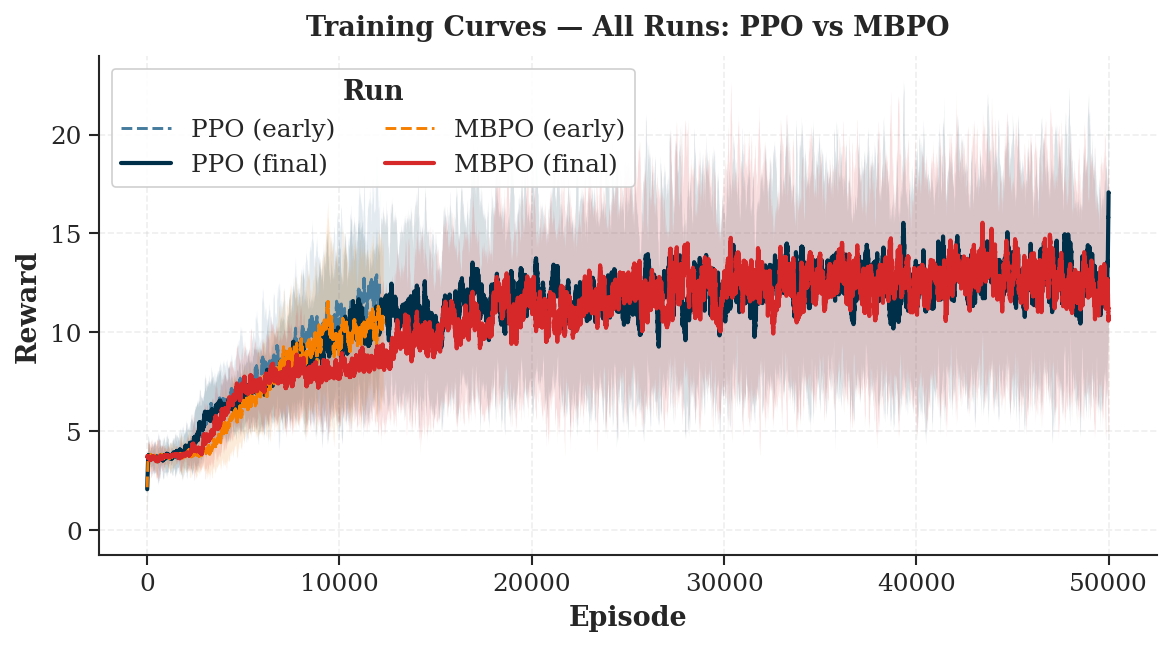

Saved → fig1_training_curves.pdf / .png


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Draw early runs first (background), final runs on top
RUN_ORDER = ["PPO (early)", "PPO (final)", "MBPO (early)", "MBPO (final)"]
LINESTYLES = {"early": (5, 3), "final": None}   # dashed for early, solid for final

for run in RUN_ORDER:
    grp = rewards[rewards["run"] == run]
    if grp.empty:
        continue
    color = PALETTE[run]
    is_final = "final" in run
    ls = "-" if is_final else "--"
    lw = 2.0 if is_final else 1.4
    ax.plot(grp["step"], grp["smooth"],
            label=run, color=color, linewidth=lw, linestyle=ls, zorder=3)
    ax.fill_between(grp["step"], grp["lo"], grp["hi"],
                    color=color, alpha=0.15, linewidth=0, zorder=2)

ax.set_xlabel("Episode")
ax.set_ylabel("Reward")
ax.set_title("Training Curves — All Runs: PPO vs MBPO",
             fontweight="bold", pad=10)
leg = ax.legend(title="Run", loc="upper left", ncol=2)
leg.get_title().set_fontweight("bold")
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("fig1_training_curves.pdf", bbox_inches="tight")
plt.savefig("fig1_training_curves.png", bbox_inches="tight")
plt.show()
print("Saved → fig1_training_curves.pdf / .png")


## 5. Figure 2 — Reward Distribution (violin + strip)

/var/folders/cl/kfvcsp8s2v9840y_1hks2dc80000gn/T/ipykernel_1367/1679794471.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Early", "Final"])
/var/folders/cl/kfvcsp8s2v9840y_1hks2dc80000gn/T/ipykernel_1367/1679794471.py:25: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Early", "Final"])


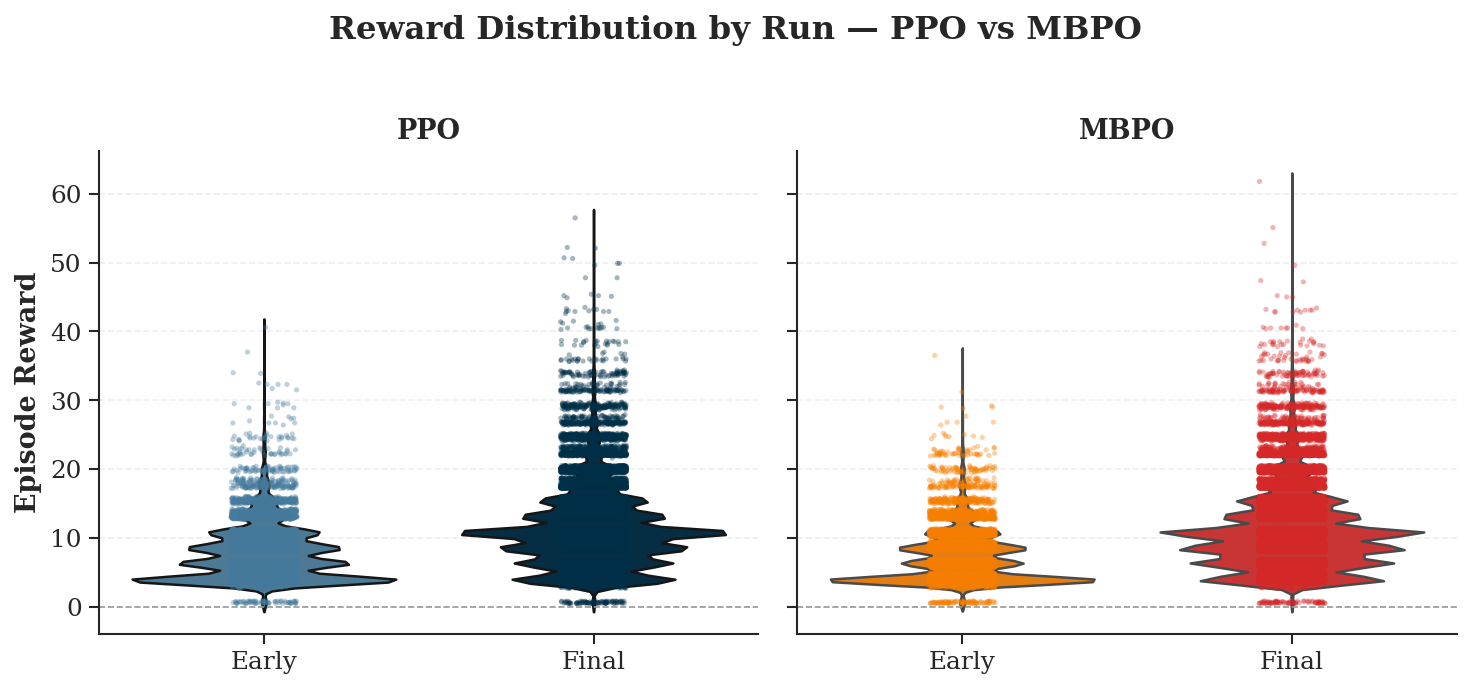

Saved → fig2_reward_distribution.pdf / .png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)

for ax, subset_label, title in [
    (axes[0], ["PPO (early)", "PPO (final)"], "PPO"),
    (axes[1], ["MBPO (early)", "MBPO (final)"], "MBPO"),
]:
    sub = rewards[rewards["run"].isin(subset_label)]
    sns.violinplot(
        data=sub, x="run", y="value",
        hue="run",
        palette={r: PALETTE[r] for r in subset_label},
        inner=None, linewidth=1.2,
        order=subset_label, ax=ax, saturation=0.85, legend=False,
    )
    sns.stripplot(
        data=sub, x="run", y="value",
        hue="run",
        palette={r: PALETTE[r] for r in subset_label},
        size=2.5, alpha=0.35, jitter=True,
        order=subset_label, ax=ax, legend=False,
    )
    ax.set_xlabel("")
    ax.set_title(title, fontweight="bold")
    ax.axhline(0, color="0.6", linewidth=0.8, linestyle="--")
    ax.set_xticklabels(["Early", "Final"])
    sns.despine(ax=ax)

axes[0].set_ylabel("Episode Reward")
axes[1].set_ylabel("")
fig.suptitle("Reward Distribution by Run — PPO vs MBPO",
             fontweight="bold", y=1.02)

plt.tight_layout()
plt.savefig("fig2_reward_distribution.pdf", bbox_inches="tight")
plt.savefig("fig2_reward_distribution.png", bbox_inches="tight")
plt.show()
print("Saved → fig2_reward_distribution.pdf / .png")


## 6. Figure 3 — Policy Loss Curves

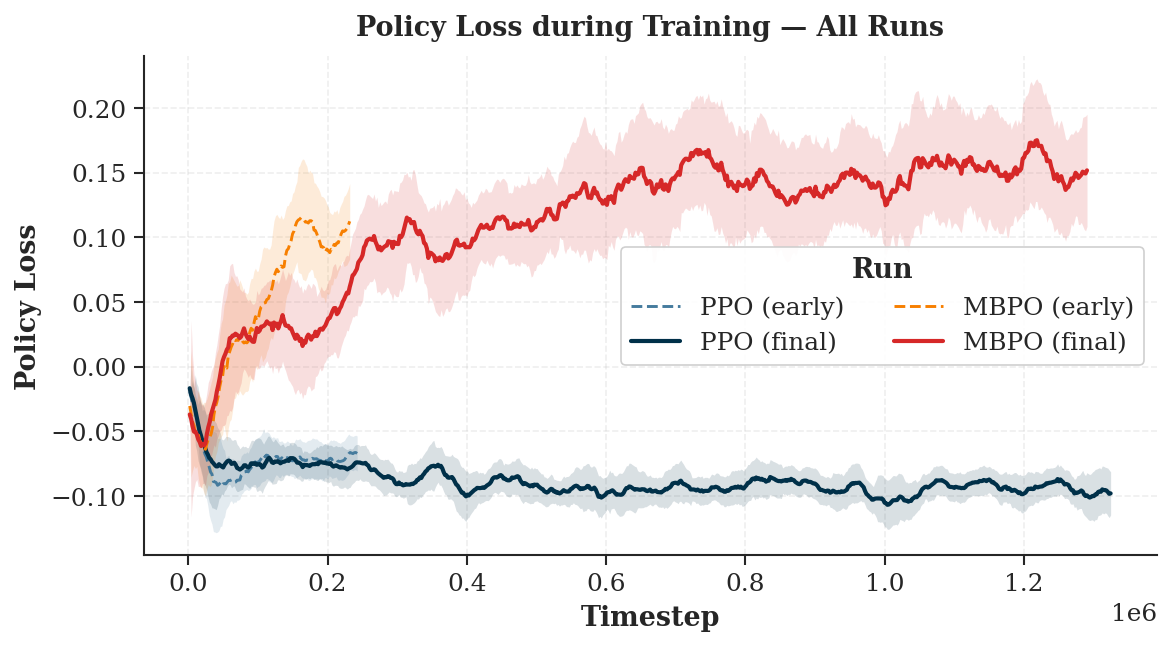

Saved → fig3_policy_loss.pdf / .png


In [ ]:
POLICY_TAG = "Policy Loss"

fig, ax = plt.subplots(figsize=(8, 4.5))

for run in RUN_ORDER:
    data = all_runs.get(run, {})
    if POLICY_TAG not in data:
        continue
    df    = data[POLICY_TAG]
    color = PALETTE[run]
    sv    = smooth(df["value"].values, SMOOTH_WIN)
    ls    = "-" if "final" in run else "--"
    lw    = 2.0 if "final" in run else 1.4
    ax.plot(df["step"], sv, label=run, color=color, linewidth=lw, linestyle=ls)
    ax.fill_between(
        df["step"],
        sv - df["value"].rolling(SMOOTH_WIN, min_periods=1).std().fillna(0),
        sv + df["value"].rolling(SMOOTH_WIN, min_periods=1).std().fillna(0),
        color=color, alpha=0.15, linewidth=0,
    )

ax.set_xlabel("Timestep")
ax.set_ylabel("Policy Loss")
ax.set_title("Policy Loss during Training — All Runs", fontweight="bold", pad=10)
leg = ax.legend(title="Run", ncol=2)
leg.get_title().set_fontweight("bold")
sns.despine(ax=ax)

plt.tight_layout()
plt.savefig("fig3_policy_loss.pdf", bbox_inches="tight")
plt.savefig("fig3_policy_loss.png", bbox_inches="tight")
plt.show()
print("Saved → fig3_policy_loss.pdf / .png")


## 7. Figure 4 — Combined 2×2 Panel (publication layout)

/var/folders/cl/kfvcsp8s2v9840y_1hks2dc80000gn/T/ipykernel_1367/2969695264.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["PPO", "MBPO"])


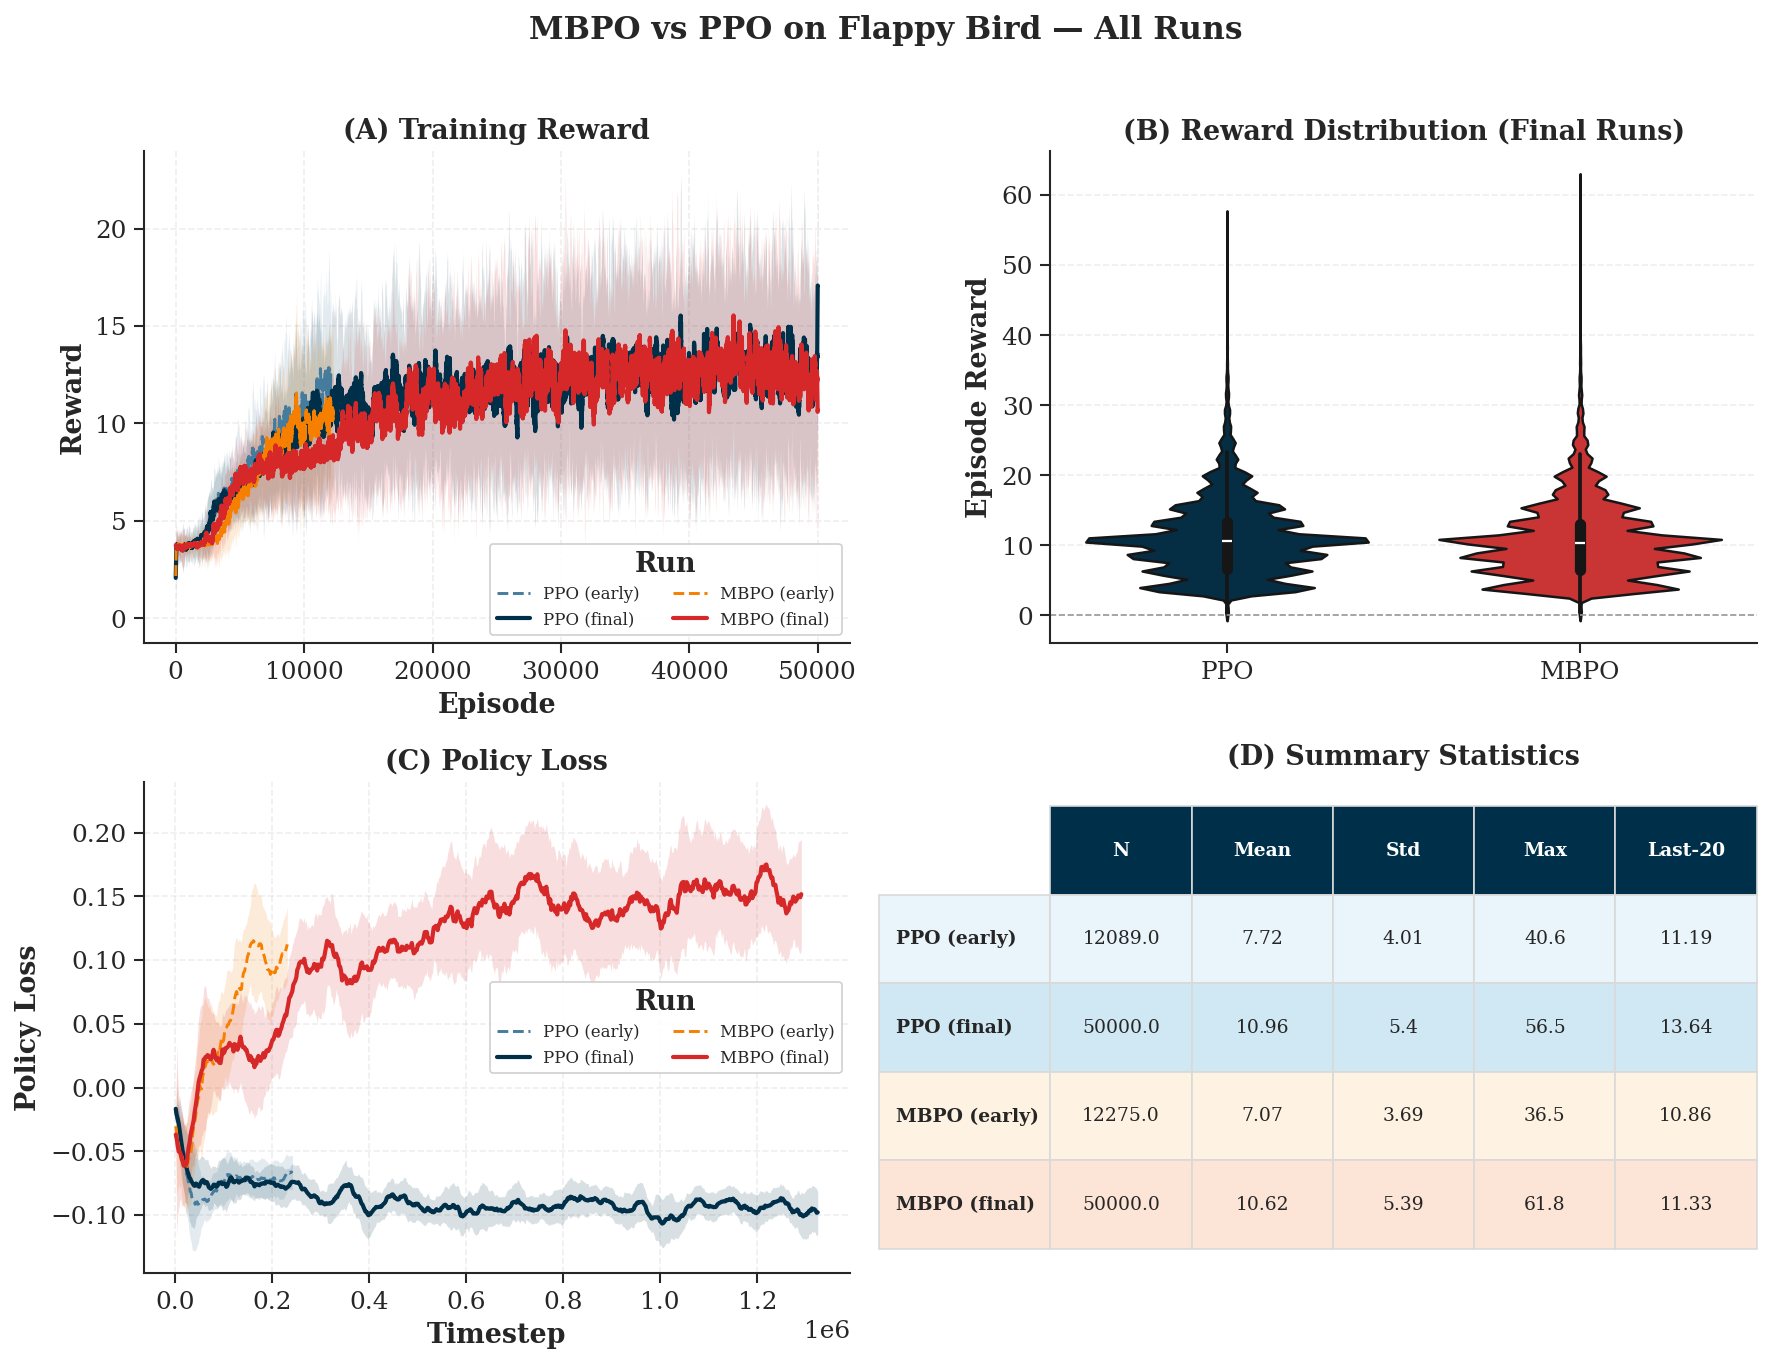

Saved → fig4_combined_panel.pdf / .png


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("MBPO vs PPO on Flappy Bird — All Runs",
             fontsize=15, fontweight="bold", y=1.01)

# ── A: Training curves (all runs) ───────────────────────────────────────────
ax = axes[0, 0]
for run in RUN_ORDER:
    grp = rewards[rewards["run"] == run]
    if grp.empty:
        continue
    c  = PALETTE[run]
    ls = "-" if "final" in run else "--"
    lw = 2.0 if "final" in run else 1.4
    ax.plot(grp["step"], grp["smooth"], label=run, color=c, linewidth=lw, linestyle=ls)
    ax.fill_between(grp["step"], grp["lo"], grp["hi"], color=c, alpha=0.15, linewidth=0)
ax.set_xlabel("Episode"); ax.set_ylabel("Reward")
ax.set_title("(A) Training Reward", fontweight="bold")
leg = ax.legend(title="Run", fontsize=8, ncol=2)
leg.get_title().set_fontweight("bold")
sns.despine(ax=ax)

# ── B: Violin — final runs only ──────────────────────────────────────────────
ax = axes[0, 1]
final_runs = rewards[rewards["run"].isin(["PPO (final)", "MBPO (final)"])]
sns.violinplot(
    data=final_runs, x="run", y="value",
    hue="run",
    palette={"PPO (final)": PALETTE["PPO (final)"], "MBPO (final)": PALETTE["MBPO (final)"]},
    inner="box", linewidth=1.2,
    order=["PPO (final)", "MBPO (final)"],
    ax=ax, saturation=0.85, legend=False,
)
ax.set_xlabel(""); ax.set_ylabel("Episode Reward")
ax.set_title("(B) Reward Distribution (Final Runs)", fontweight="bold")
ax.set_xticklabels(["PPO", "MBPO"])
ax.axhline(0, color="0.6", linewidth=0.8, linestyle="--")
sns.despine(ax=ax)

# ── C: Policy loss (all runs) ────────────────────────────────────────────────
ax = axes[1, 0]
for run in RUN_ORDER:
    data = all_runs.get(run, {})
    if POLICY_TAG not in data:
        continue
    df    = data[POLICY_TAG]
    sv    = smooth(df["value"].values, SMOOTH_WIN)
    c     = PALETTE[run]
    ls    = "-" if "final" in run else "--"
    lw    = 2.0 if "final" in run else 1.4
    ax.plot(df["step"], sv, label=run, color=c, linewidth=lw, linestyle=ls)
    ax.fill_between(
        df["step"],
        sv - df["value"].rolling(SMOOTH_WIN, min_periods=1).std().fillna(0),
        sv + df["value"].rolling(SMOOTH_WIN, min_periods=1).std().fillna(0),
        color=c, alpha=0.15, linewidth=0,
    )
ax.set_xlabel("Timestep"); ax.set_ylabel("Policy Loss")
ax.set_title("(C) Policy Loss", fontweight="bold")
leg = ax.legend(title="Run", fontsize=8, ncol=2)
leg.get_title().set_fontweight("bold")
sns.despine(ax=ax)

# ── D: Summary statistics table ──────────────────────────────────────────────
ax = axes[1, 1]
ax.axis("off")

stats = (
    rewards.groupby("run")["value"]
    .agg(N="count", Mean="mean", Std="std", Max="max")
    .reindex(RUN_ORDER)
    .round(2)
)
stats["Last-20"] = (
    rewards.groupby("run")["value"]
    .apply(lambda x: x.iloc[-20:].mean())
    .reindex(RUN_ORDER)
    .round(2)
)

tbl = ax.table(
    cellText=stats.values,
    rowLabels=stats.index,
    colLabels=stats.columns,
    cellLoc="center",
    loc="center",
    bbox=[0.0, 0.05, 1.0, 0.90],
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
header_color = "#003049"
row_colors   = ["#EAF4FB", "#D0E8F3", "#FEF3E2", "#FCE4D6"]
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("0.85")
    if r == 0:
        cell.set_facecolor(header_color)
        cell.set_text_props(color="white", fontweight="bold")
    elif c == -1:
        idx = r - 1
        cell.set_facecolor(row_colors[idx] if idx < len(row_colors) else "white")
        cell.set_text_props(fontweight="bold")
    else:
        idx = r - 1
        cell.set_facecolor(row_colors[idx] if idx < len(row_colors) else "white")

ax.set_title("(D) Summary Statistics", fontweight="bold", pad=8)

plt.tight_layout()
plt.savefig("fig4_combined_panel.pdf", bbox_inches="tight")
plt.savefig("fig4_combined_panel.png", bbox_inches="tight")
plt.show()
print("Saved → fig4_combined_panel.pdf / .png")


## 8. Numerical Summary

In [ ]:
summary = (
    rewards.groupby("run")["value"]
    .agg(Episodes="count", Mean="mean", Std="std", Min="min", Max="max")
    .reindex(RUN_ORDER)
    .round(4)
)
summary["Last-20 Mean"] = (
    rewards.groupby("run")["value"]
    .apply(lambda x: x.iloc[-20:].mean())
    .reindex(RUN_ORDER)
    .round(4)
)

print("=" * 68)
print(f"{'MBPO vs PPO — Flappy Bird (All Runs)':^68}")
print("=" * 68)
print(summary.to_string())
print("=" * 68)


                MBPO vs PPO — Flappy Bird (All Runs)                
              Episodes     Mean     Std  Min   Max  Last-20 Mean
run                                                             
PPO (early)      12089   7.7178  4.0057  0.5  40.6        11.195
PPO (final)      50000  10.9565  5.3982  0.5  56.5        13.645
MBPO (early)     12275   7.0713  3.6903  0.5  36.5        10.865
MBPO (final)     50000  10.6235  5.3879  0.5  61.8        11.335
